In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
def create_polynomial_features(X, degree):
    X = np.asarray(X, dtype = float).reshape(-1)

    features = []
    for d in range(degree + 1):
        feature = X ** d
        features.append(feature)
    return np.column_stack(features)

In [2]:
X = np.array([0, 1, 2, 3, 4, 5])

X_poly = create_polynomial_features(
    X,
    degree=2
)

print(X_poly)
print(X_poly.shape)

[[ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]
(6, 3)


In [3]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures

X = np.array([0, 1, 2, 3, 4, 5]).reshape(-1, 1)

poly = PolynomialFeatures(
    degree=2,
    include_bias=True
)

X_poly = poly.fit_transform(X)

print(X_poly)
print("Shape:", X_poly.shape)


[[ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]
Shape: (6, 3)


In [4]:
df = pd.read_csv('data/Salaries.csv')
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [5]:
X = df.Level
X

0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10
Name: Level, dtype: int64

In [6]:
y = df.Salary
y

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64

Text(0, 0.5, 'Salary')

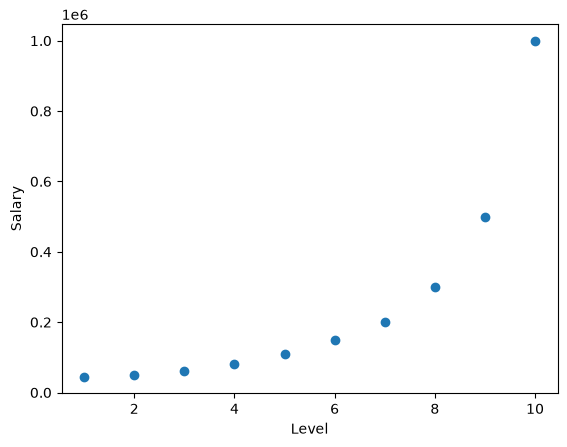

In [7]:
plt.scatter(X, y)
plt.xlabel('Level')
plt.ylabel('Salary')

In [8]:
def r2score(y_pred, y):
    rss = np.sum((y_pred - y) ** 2)
    tss = np.sum((y - y.mean()) ** 2)
    r2 = 1 - (rss / tss)
    return r2

In [9]:
class LinearRegression:
    def __init__(self, X_data, y_target, learning_rate = 0.01, num_epochs = 10000):
        self.X_data = X_data
        self.y_target = y_target
        self.learning_rate = learning_rate
        self.num_epochs = num_epochs
        self.num_samples = self.X_data.shape[0]
        self.theta = np.random.randn(self.X_data.shape[1])
        self.losses = []
    def compute_loss(self, y_pred, y_target):
        loss = (y_pred - y_target) ** 2
        loss = np.mean(loss)
        return loss
    def predict(self, X_data):
        y_pred = X_data.dot(self.theta)
        return y_pred
    def fit(self):
        for epoch in range(self.num_epochs):
            y_pred = self.predict(self.X_data)
            loss = self.compute_loss(y_pred, self.y_target)
            self.losses.append(loss)

            k = 2 * (y_pred - self.y_target)
            gradients = self.X_data.T.dot(k) / self.num_samples

            self.theta = self.theta - self.learning_rate * gradients
            print(f'Epoch: {epoch} - Loss : {loss}')
        return {
            'loss': sum(self.losses) / len(self.losses),
            'weight': self.theta
        }


In [10]:
X_linear = X.values.reshape(-1, 1)
print(X_linear)
X_linear = np.hstack((np.ones((X_linear.shape[0], 1)), X_linear))
print(X_linear)

[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]]
[[ 1.  1.]
 [ 1.  2.]
 [ 1.  3.]
 [ 1.  4.]
 [ 1.  5.]
 [ 1.  6.]
 [ 1.  7.]
 [ 1.  8.]
 [ 1.  9.]
 [ 1. 10.]]


In [11]:
linear_model = LinearRegression(X_linear, y, learning_rate = 0.02, num_epochs = 100)
linear_model.fit()

Epoch: 0 - Loss : 142906876742.70105
Epoch: 1 - Loss : 70450142497.05032
Epoch: 2 - Loss : 46679758731.29183
Epoch: 3 - Loss : 38818168744.99072
Epoch: 4 - Loss : 36156012597.18349
Epoch: 5 - Loss : 35194220052.51665
Epoch: 6 - Loss : 34789522066.27742
Epoch: 7 - Loss : 34568355331.61902
Epoch: 8 - Loss : 34408641090.799194
Epoch: 9 - Loss : 34270467955.915077
Epoch: 10 - Loss : 34140771303.982544
Epoch: 11 - Loss : 34015258500.771656
Epoch: 12 - Loss : 33892503365.4857
Epoch: 13 - Loss : 33772016662.569324
Epoch: 14 - Loss : 33653615671.48235
Epoch: 15 - Loss : 33537218201.227528
Epoch: 16 - Loss : 33422775282.80854
Epoch: 17 - Loss : 33310249171.704052
Epoch: 18 - Loss : 33199606154.480614
Epoch: 19 - Loss : 33090814192.42981
Epoch: 20 - Loss : 32983842145.69682
Epoch: 21 - Loss : 32878659513.899048
Epoch: 22 - Loss : 32775236345.59478
Epoch: 23 - Loss : 32673543203.01665
Epoch: 24 - Loss : 32573551144.95661
Epoch: 25 - Loss : 32475231715.675262
Epoch: 26 - Loss : 32378556935.871265


{'loss': np.float64(32583552462.460045),
 'weight': array([-108098.85421309,   68348.37924494])}

In [12]:
y_pred = linear_model.predict(X_linear)

In [13]:
print(r2score(y_pred, y))

0.6488228177121522


In [14]:
linear_model.theta

array([-108098.85421309,   68348.37924494])

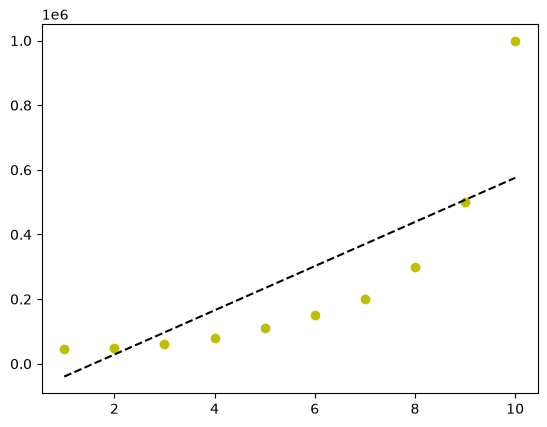

In [15]:
plt.plot(X, y, 'yo', X, linear_model.theta[1] * X + linear_model.theta[0], '--k')
plt.show()

In [16]:
X_poly = create_polynomial_features(X, degree = 2)
X_poly

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.]])

In [17]:
poly_model = LinearRegression(X_poly, y, learning_rate = 0.00001, num_epochs = 100)
poly_model.fit()

Epoch: 0 - Loss : 142916205189.38315
Epoch: 1 - Loss : 130164333329.68022
Epoch: 2 - Loss : 118689636052.03886
Epoch: 3 - Loss : 108364191962.10172
Epoch: 4 - Loss : 99072892231.64114
Epoch: 5 - Loss : 90712157296.0151
Epoch: 6 - Loss : 83188782086.79698
Epoch: 7 - Loss : 76418896925.538
Epoch: 8 - Loss : 70327032494.07918
Epoch: 9 - Loss : 64845278457.13932
Epoch: 10 - Loss : 59912526356.99663
Epoch: 11 - Loss : 55473788339.598
Epoch: 12 - Loss : 51479584116.84425
Epoch: 13 - Loss : 47885389330.537895
Epoch: 14 - Loss : 44651139168.02183
Epoch: 15 - Loss : 41740781695.51802
Epoch: 16 - Loss : 39121875929.456665
Epoch: 17 - Loss : 36765230164.85289
Epoch: 18 - Loss : 34644576528.59835
Epoch: 19 - Loss : 32736278129.391243
Epoch: 20 - Loss : 31019065539.43638
Epoch: 21 - Loss : 29473799670.053997
Epoch: 22 - Loss : 28083258397.59239
Epoch: 23 - Loss : 26831944560.82087
Epoch: 24 - Loss : 25705913189.242992
Epoch: 25 - Loss : 24692616036.166782
Epoch: 26 - Loss : 23780761683.29315
Epoch:

{'loss': np.float64(28292004531.12019),
 'weight': array([  57.0607319 ,  618.24685006, 6978.03597099])}

In [18]:
y_pred = poly_model.predict(X_poly)
r2score(y_pred, y)

np.float64(0.8070916851846502)

In [22]:
poly_model.theta

array([  57.0607319 ,  618.24685006, 6978.03597099])

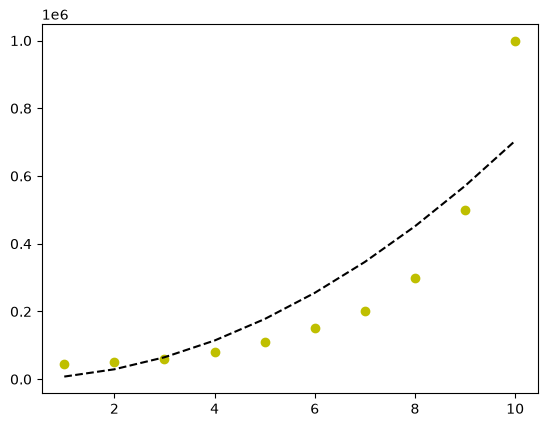

In [25]:
X_plot = df.Level
y_func = poly_model.theta[2] * X * X + poly_model.theta[1] * X + poly_model.theta[0]
plt.plot(X_plot, y, 'yo', X, y_func, '--k')
plt.show()

In [29]:
# Polymial Regression with degree = 3
X_poly = create_polynomial_features(X, degree = 3)
X_poly

array([[   1.,    1.,    1.,    1.],
       [   1.,    2.,    4.,    8.],
       [   1.,    3.,    9.,   27.],
       [   1.,    4.,   16.,   64.],
       [   1.,    5.,   25.,  125.],
       [   1.,    6.,   36.,  216.],
       [   1.,    7.,   49.,  343.],
       [   1.,    8.,   64.,  512.],
       [   1.,    9.,   81.,  729.],
       [   1.,   10.,  100., 1000.]])

In [30]:
poly_model = LinearRegression(X_poly, y, learning_rate = 0.000001, num_epochs = 100)
poly_model.fit()

Epoch: 0 - Loss : 143201124523.28644
Epoch: 1 - Loss : 55935826037.38487
Epoch: 2 - Loss : 24590994701.35859
Epoch: 3 - Loss : 13332047035.95094
Epoch: 4 - Loss : 9287680123.386013
Epoch: 5 - Loss : 7834694174.062639
Epoch: 6 - Loss : 7312497682.107407
Epoch: 7 - Loss : 7124628397.357915
Epoch: 8 - Loss : 7056845060.2159605
Epoch: 9 - Loss : 7032195076.76358
Epoch: 10 - Loss : 7023038104.867922
Epoch: 11 - Loss : 7019446103.4377165
Epoch: 12 - Loss : 7017853052.924571
Epoch: 13 - Loss : 7016978086.794275
Epoch: 14 - Loss : 7016361134.899859
Epoch: 15 - Loss : 7015836946.174383
Epoch: 16 - Loss : 7015346164.619777
Epoch: 17 - Loss : 7014867470.329829
Epoch: 18 - Loss : 7014393205.453608
Epoch: 19 - Loss : 7013920619.367653
Epoch: 20 - Loss : 7013448724.058958
Epoch: 21 - Loss : 7012977164.620604
Epoch: 22 - Loss : 7012505813.548935
Epoch: 23 - Loss : 7012034625.020495
Epoch: 24 - Loss : 7011563582.550287
Epoch: 25 - Loss : 7011092680.191287
Epoch: 26 - Loss : 7010621915.781586
Epoch: 27

{'loss': np.float64(9124738684.203882),
 'weight': array([2.43781193e+00, 5.04633034e-01, 2.57951244e+01, 8.25887732e+02])}

In [31]:
y_pred = poly_model.predict(X_poly)
r2score(y_pred, y)

np.float64(0.9135139164752869)

In [32]:
poly_model.theta

array([2.43781193e+00, 5.04633034e-01, 2.57951244e+01, 8.25887732e+02])

0       854.625302
1      6713.729434
2     22535.076603
3     53273.993203
4    103885.805627
5    179325.840269
6    284549.423523
7    424511.881784
8    604168.541445
9    828474.728899
Name: Level, dtype: float64


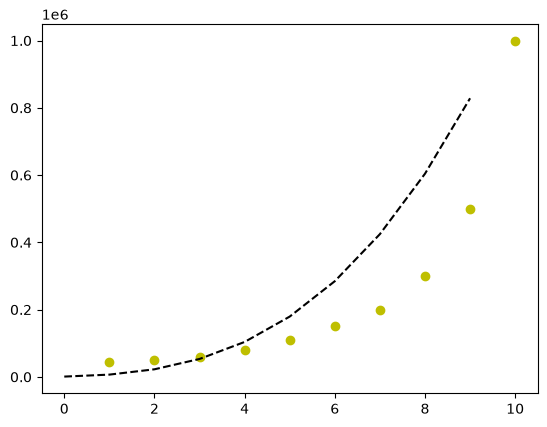

In [38]:
X_plot = df.Level
y_func = poly_model.theta[3] * X * X * X + poly_model.theta[2] * X * X + poly_model.theta[1] * X + poly_model.theta[0]

print(y_func)
plt.plot(X_plot, y, 'yo', y_func, '--k')
plt.show()

In [43]:
from scipy import optimize

def func(x, a, b):
    y = a * x + b
    return y

In [39]:
X

0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10
Name: Level, dtype: int64

In [40]:
y

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64

In [44]:
optimize.curve_fit(func, xdata = X, ydata = y)

(array([  80878.78770337, -195333.33316347]),
 array([[ 4.04483016e+08, -2.22465659e+09],
        [-2.22465659e+09,  1.55725960e+10]]))

In [ ]:
alpha, beta = optimize.curve_fit(func, xdata = X, ydata = y)[0]
print(f'alpha = {alpha}, beta = {beta}')